In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay)

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)


In [ ]:
df = pd.read_csv("bank_notes.csv")

In [ ]:
df.head()

,variance,skewness,curtosis,entropy,Target
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


### 1. Basic Dataset Information & Missing Values Check
Let's check the shape, column data types, summary statistics, and whether there are any missing values in the dataset.

In [ ]:
print("=== Dataset Shape ===")
print(df.shape)

print("\n=== Info ===")
df.info()

print("\n=== Missing Values ===")
print(df.isnull().sum())

print("\n=== Summary Statistics ===")
display(df.describe())

=== Dataset Shape ===
(1372, 5)

=== Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   curtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
 4   Target    1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB

=== Missing Values ===
variance    0
skewness    0
curtosis    0
entropy     0
Target      0
dtype: int64

=== Summary Statistics ===


,variance,skewness,curtosis,entropy,Target
count,1372.000000,1372.000000,1372.000000,1372.000000,1372.000000
mean,0.433735,1.922353,1.397627,-1.191657,0.444606
std,2.842763,5.869047,4.310030,2.101013,0.497103
min,-7.042100,-13.773100,-5.286100,-8.548200,0.000000
25%,-1.773000,-1.708200,-1.574975,-2.413450,0.000000
50%,0.496180,2.319650,0.616630,-0.586650,0.000000
75%,2.821475,6.814625,3.179250,0.394810,1.000000
max,6.824800,12.951600,17.927400,2.449500,1.000000


### 2. Handling Duplicate Values
Now we will check for duplicate rows and drop them if any exist to ensure data integrity.

In [ ]:
duplicate_count = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_count}")

if duplicate_count > 0:
    df = df.drop_duplicates()
    print("Duplicates removed successfully!")
    print(f"New dataset shape: {df.shape}")
else:
    print("No duplicate rows found.")

Number of duplicate rows: 24
Duplicates removed successfully!
New dataset shape: (1348, 5)


### 3. Target Variable Distribution
Let's check the balance of the target variable `Target` to understand the distribution of genuine versus forged bank notes.

Target distribution:
Target
0    738
1    610
Name: count, dtype: int64


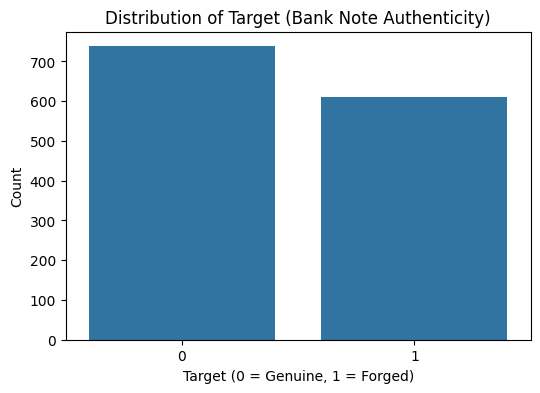

In [ ]:
target_counts = df['Target'].value_counts()
print("Target distribution:")
print(target_counts)

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Target')
plt.title('Distribution of Target (Bank Note Authenticity)')
plt.xlabel('Target (0 = Genuine, 1 = Forged)')
plt.ylabel('Count')
plt.show()

### 4. Advanced Visualizations for EDA
We will now generate various plots to analyze the feature distributions, outlier presence, correlations, and feature relationships.

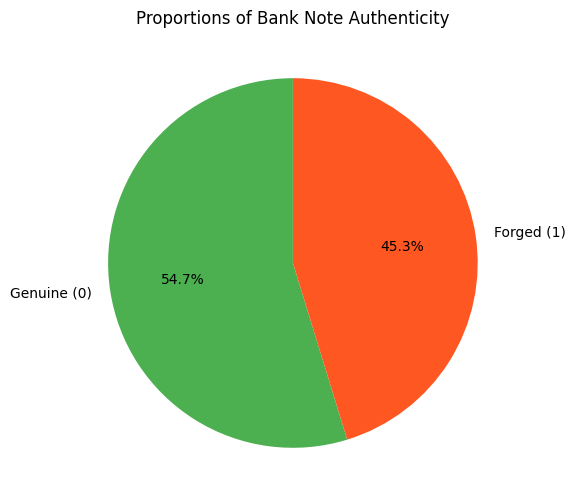

In [ ]:
# 1. Pie Chart of the Target variable
plt.figure(figsize=(6, 6))
plt.pie(target_counts, labels=['Genuine (0)', 'Forged (1)'], autopct='%1.1f%%', startangle=90, colors=['#4CAF50', '#FF5722'])
plt.title('Proportions of Bank Note Authenticity')
plt.show()

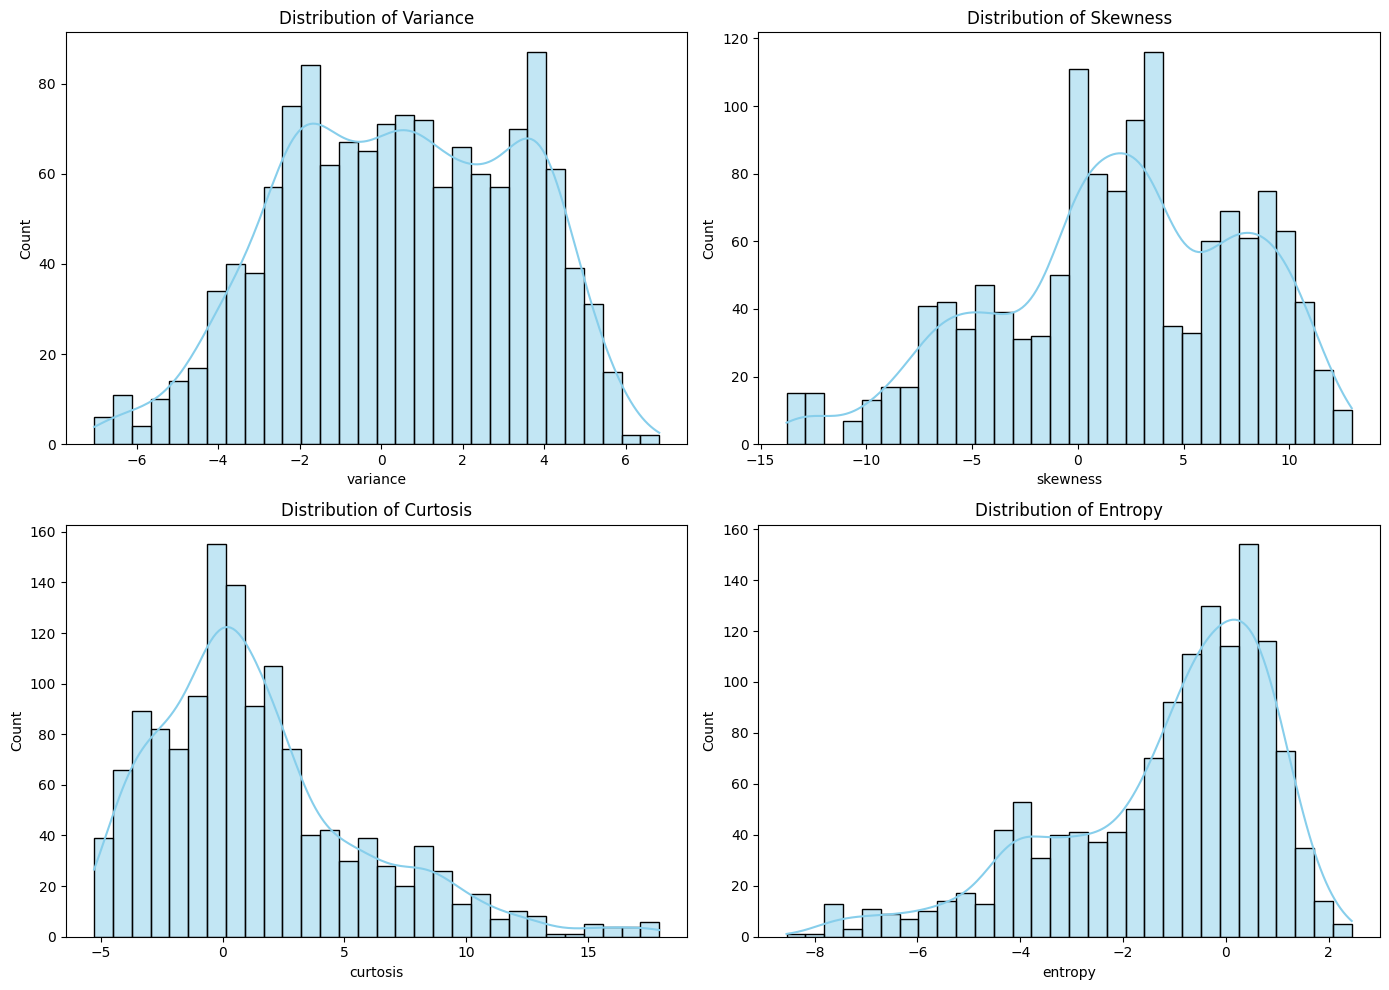

In [ ]:
# 2. Simple Histograms with KDE for each feature
features = df.columns[:-1]
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.histplot(data=df, x=col, kde=True, ax=axes[i], color='skyblue', bins=30)
    axes[i].set_title(f'Distribution of {col.capitalize()}')

plt.tight_layout()
plt.show()

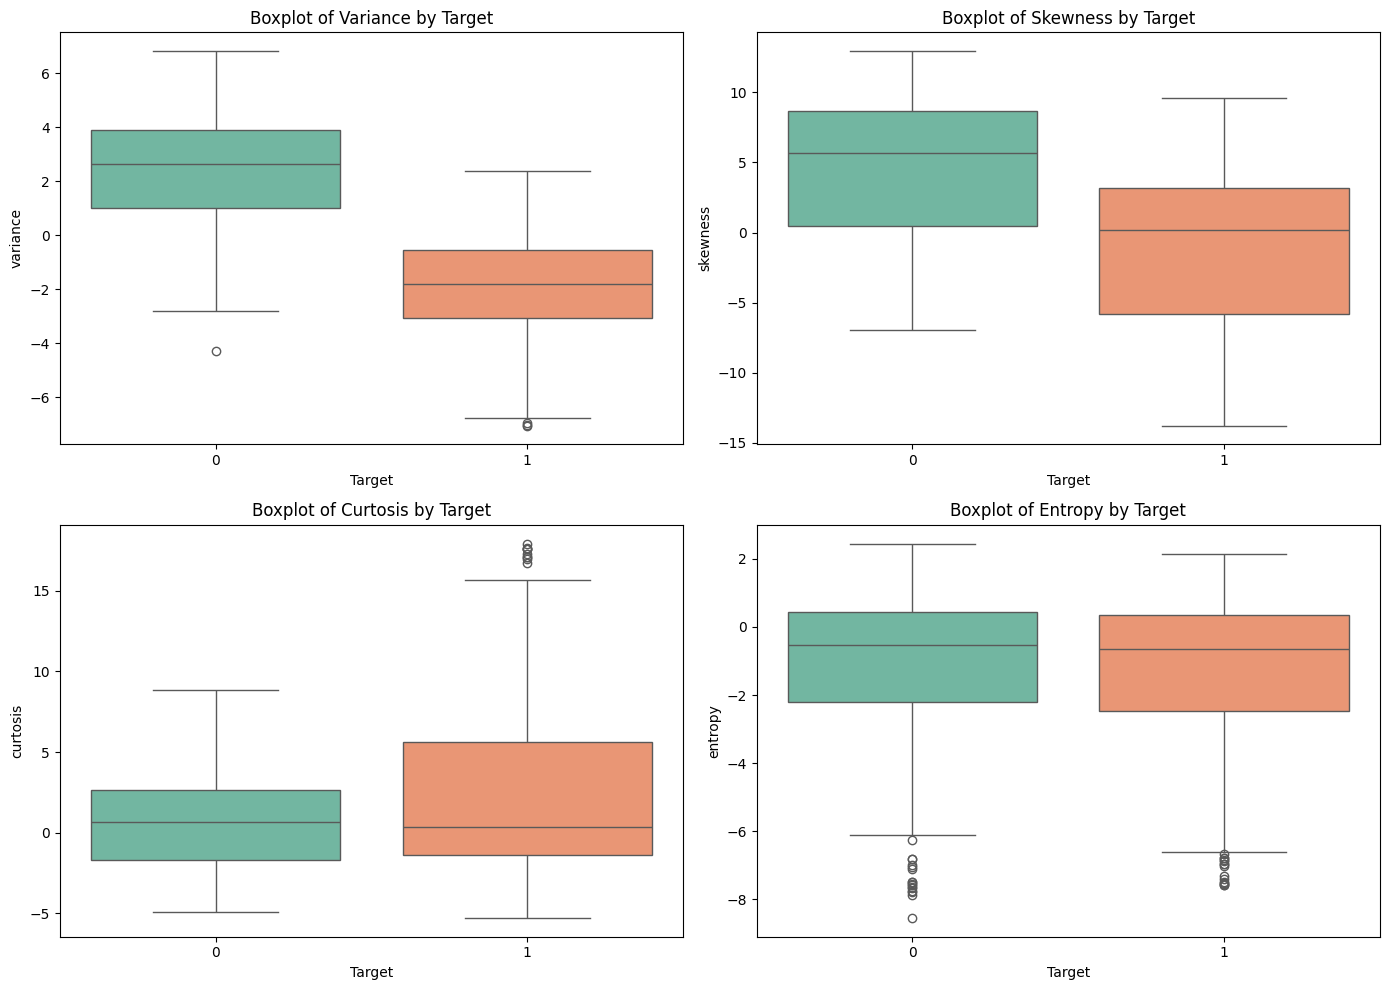

In [ ]:
# 3. Boxplots for outlier detection
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.boxplot(data=df, y=col, x='Target', ax=axes[i], palette='Set2')
    axes[i].set_title(f'Boxplot of {col.capitalize()} by Target')

plt.tight_layout()
plt.show()

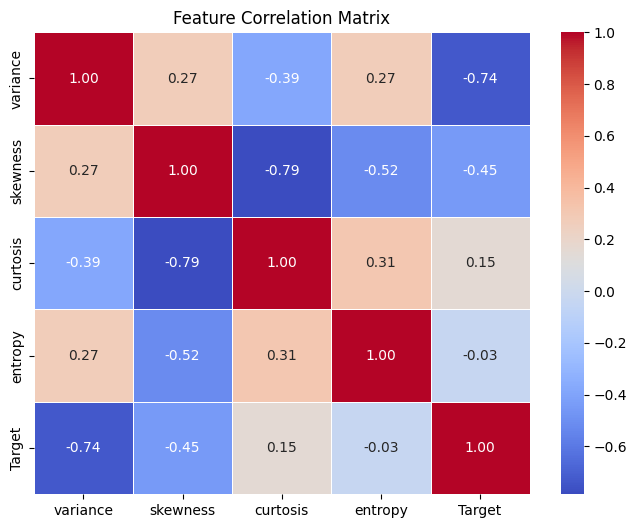

In [ ]:
# 4. Correlation Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Feature Correlation Matrix')
plt.show()

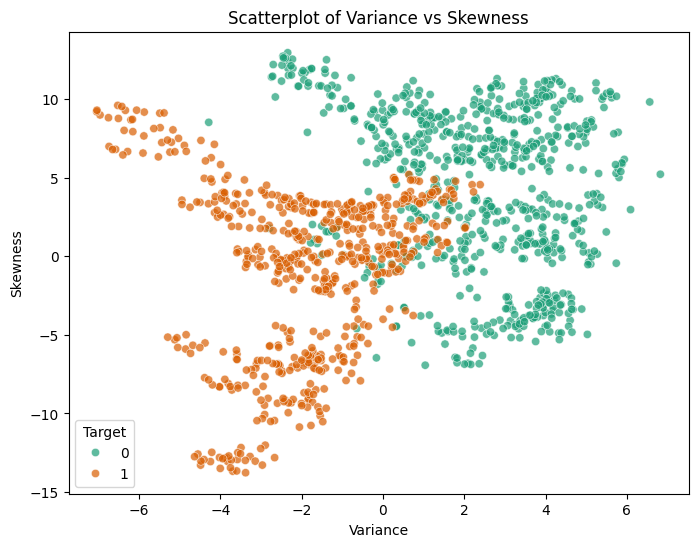

In [ ]:
# 5. Scatterplot of Variance vs Skewness colored by Target
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='variance', y='skewness', hue='Target', palette='Dark2', alpha=0.7)
plt.title('Scatterplot of Variance vs Skewness')
plt.xlabel('Variance')
plt.ylabel('Skewness')
plt.show()

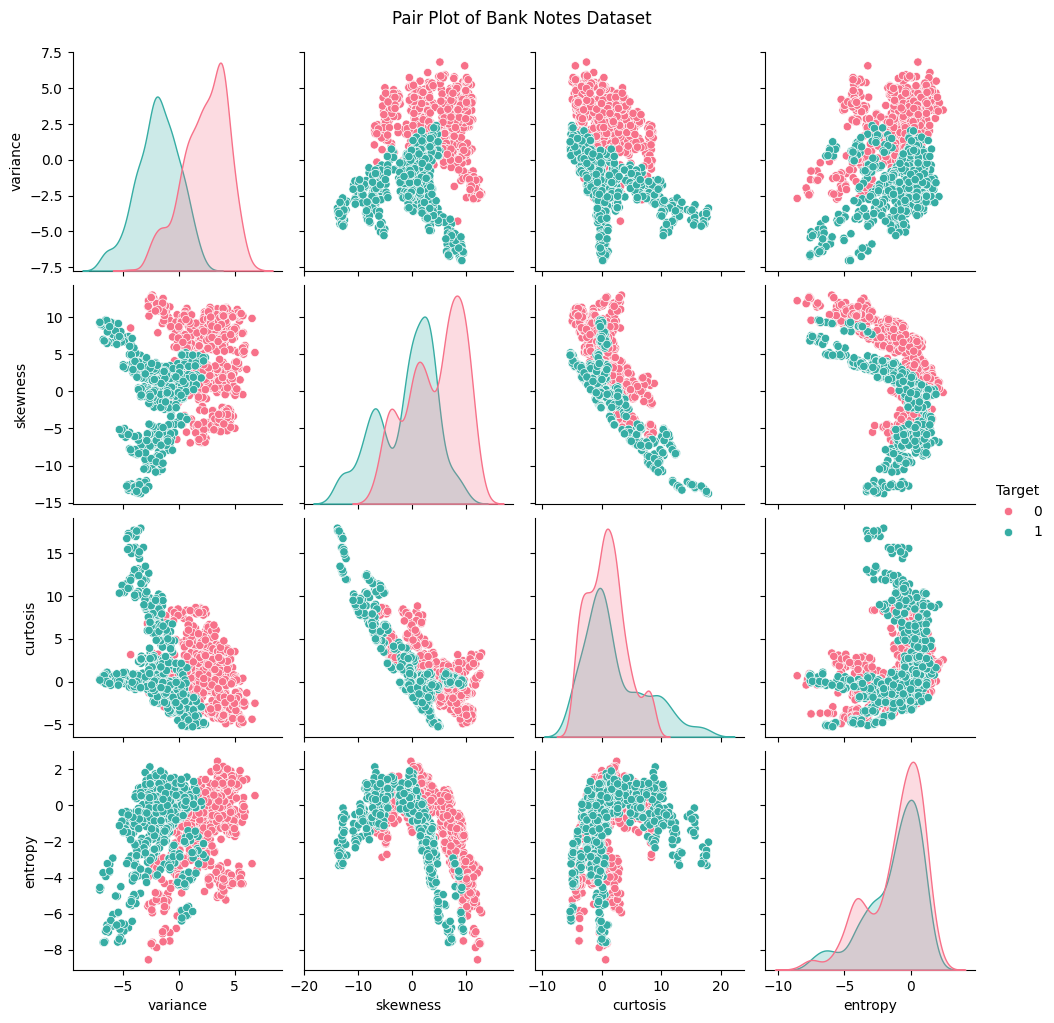

In [ ]:
# 6. Pair Plot of all variables
sns.pairplot(df, hue='Target', palette='husl', diag_kind='kde')
plt.suptitle('Pair Plot of Bank Notes Dataset', y=1.02)
plt.show()

### 5. Outlier Removal using IQR Method
We will remove outliers from the continuous feature columns by identifying values that lie beyond 1.5 times the Interquartile Range (IQR) from the first and third quartiles.

In [ ]:
print(f"Shape before outlier removal: {df.shape}")

features_to_clean = ['variance', 'skewness', 'curtosis', 'entropy']

# Calculate IQR bounds
Q1 = df[features_to_clean].quantile(0.25)
Q3 = df[features_to_clean].quantile(0.75)
IQR = Q3 - Q1

# Define boolean filter to keep rows within 1.5 * IQR bounds
filter_mask = ~((df[features_to_clean] < (Q1 - 1.5 * IQR)) | (df[features_to_clean] > (Q3 + 1.5 * IQR))).any(axis=1)

# Apply filter
df_cleaned = df[filter_mask]

print(f"Shape after outlier removal: {df_cleaned.shape}")
print(f"Removed {df.shape[0] - df_cleaned.shape[0]} outlier rows.")

# Assign back to df
df = df_cleaned

Shape before outlier removal: (1348, 5)
Shape after outlier removal: (1257, 5)
Removed 91 outlier rows.


In [ ]:
# Identify categorical columns in the dataset
categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

if len(categorical_cols) > 0:
    print(f"Categorical columns found to encode: {categorical_cols}")
    le = LabelEncoder()
    for col in categorical_cols:
        df[col] = le.fit_transform(df[col])
    print("Label encoding applied successfully!")
else:
    print("No categorical columns found. All features and targets are already numerical.")

display(df.head())

No categorical columns found. All features and targets are already numerical.


,variance,skewness,curtosis,entropy,Target
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [ ]:
X = df[['variance', 'skewness', 'curtosis', 'entropy']]
y = df['Target']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1257, 4)
y shape: (1257,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size =0.25, random_state=34, stratify=y)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (942, 4)
y_train shape: (942,)
X_test shape: (315, 4)
y_test shape: (315,)


In [ ]:
GaussianNB()

GaussianNB()

In [ ]:
gnb = GaussianNB()
gnb.fit(X_train, y_train)

GaussianNB()

In [ ]:
y_pred = gnb.predict(X_test)
print("Predicted label: ")
print(y_pred)

Predicted label: 
[1 1 0 1 1 0 0 1 1 0 1 1 0 0 0 0 1 0 0 1 1 1 1 1 1 0 1 0 0 1 0 1 0 0 1 0 0
 0 0 0 1 1 0 0 0 0 1 0 1 0 1 1 0 0 1 1 0 0 0 1 1 1 0 1 0 0 0 1 1 1 0 0 1 0
 0 0 1 1 0 1 0 0 1 0 0 1 0 1 0 0 1 0 0 1 1 0 0 0 0 1 1 1 0 1 1 1 1 0 1 0 0
 0 1 0 1 0 0 0 1 1 1 0 0 1 0 1 0 0 1 1 1 0 1 0 0 0 0 0 0 1 1 1 0 0 0 0 0 0
 0 0 0 1 0 0 0 1 0 1 0 0 0 1 0 0 0 1 0 1 1 1 1 0 0 1 0 0 0 1 1 1 1 0 0 1 1
 0 0 0 0 0 1 1 0 1 0 0 1 0 1 1 0 1 0 1 0 1 1 1 1 1 1 1 1 0 0 0 1 0 0 0 0 1
 0 1 0 1 1 0 0 0 0 0 0 0 0 1 0 0 0 0 1 1 0 0 0 1 1 1 0 0 0 0 1 1 0 1 0 1 0
 0 0 1 0 1 1 0 1 1 0 0 0 0 0 0 1 0 0 0 0 0 1 1 0 1 0 0 0 0 0 1 1 1 0 1 0 0
 0 0 0 0 0 1 0 0 0 0 1 0 1 1 0 0 0 0 0]


In [ ]:
comparison = pd.DataFrame({'Actual': y_test.values, 'Predicted': y_pred})
comparison.head(5)

,Actual,Predicted
0,1,1
1,1,1
2,0,0
3,1,1
4,1,1


In [ ]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

In [ ]:
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Accuracy: 0.8857142857142857
Precision: 0.8769230769230769
Recall: 0.8507462686567164
F1 Score: 0.8636363636363636


In [ ]:
print("Classification Report:\n")
print(classification_report(y_test, y_pred, target_names=['Genuine', 'Forged']))

Classification Report:

              precision    recall  f1-score   support

     Genuine       0.89      0.91      0.90       181
      Forged       0.88      0.85      0.86       134

    accuracy                           0.89       315
   macro avg       0.88      0.88      0.88       315
weighted avg       0.89      0.89      0.89       315



In [ ]:
cm = confusion_matrix(y_test,y_pred)
print("Confusion Matrix:\n")
print(cm)

Confusion Matrix:

[[165  16]
 [ 20 114]]


In [ ]:
from sklearn.metrics import accuracy_score

y_train_pred =gnb.predict(X_train)

y_test_pred = gnb.predict(X_test)

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print("Training Accuracy:", train_accuracy*100)
print("Testing Accuracy:", test_accuracy*100)



Training Accuracy: 87.15498938428875
Testing Accuracy: 88.57142857142857


In [ ]:
GaussianNB(priors = None)

GaussianNB()

In [ ]:
# Main_Hyperparameter

In [ ]:
GaussianNB(var_smoothing=1e-09)

GaussianNB()

In [ ]:
print(gnb.get_params())

{'priors': None, 'var_smoothing': 1e-09}


In [ ]:
smoothing_values = [1e-12,1e-10,1e-9,1e-8,1e-7,1e-6,1e-5,1e-4,1e-3,1e-2]
results = []

for value in smoothing_values:
  model = GaussianNB(var_smoothing=value)
  model.fit(X_train, y_train)
  prediction = model.predict(X_test)
  accuracy = accuracy_score(y_test, prediction)
  precision = precision_score(y_test, prediction)
  recall = recall_score(y_test, prediction)
  f1 = f1_score(y_test, prediction)
  results.append([value, accuracy, precision, recall, f1])


In [ ]:
results_df = pd.DataFrame(results, columns=['Smoothing Value', 'Accuracy', 'Precision', 'Recall', 'F1 Score'])
results_df


,Smoothing Value,Accuracy,Precision,Recall,F1 Score
0,1.000000e-12,0.885714,0.876923,0.850746,0.863636
1,1.000000e-10,0.885714,0.876923,0.850746,0.863636
2,1.000000e-09,0.885714,0.876923,0.850746,0.863636
3,1.000000e-08,0.885714,0.876923,0.850746,0.863636
4,1.000000e-07,0.885714,0.876923,0.850746,0.863636
5,1.000000e-06,0.885714,0.876923,0.850746,0.863636
6,1.000000e-05,0.885714,0.876923,0.850746,0.863636
7,1.000000e-04,0.885714,0.876923,0.850746,0.863636
8,1.000000e-03,0.885714,0.876923,0.850746,0.863636
9,1.000000e-02,0.885714,0.876923,0.850746,0.863636
